# Homework 4

Same lead scoring dataset as hw03, but the split uses `random_state=1` this time, not 42.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
df = pd.read_csv(url)

cat = ['lead_source', 'industry', 'employment_status', 'location']
num = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

for c in cat:
    df[c] = df[c].fillna('NA')
for c in num:
    df[c] = df[c].fillna(0.0)

df.isna().sum().sum()


np.int64(0)

In [2]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.pop('converted').values
y_val = df_val.pop('converted').values
y_test = df_test.pop('converted').values

len(df_train), len(df_val), len(df_test)


(3000, 1000, 1000)

## Q1 - ROC AUC as feature importance


In [3]:
aucs = {}
for c in num:
    score = roc_auc_score(y_train, df_train[c])
    if score < 0.5:
        score = roc_auc_score(y_train, -df_train[c])
    aucs[c] = score

pd.Series(aucs).sort_values(ascending=False).round(4)


lead_score                  0.7882
interaction_count           0.7649
number_of_courses_viewed    0.7230
annual_income               0.6082
dtype: float64

**Q1: `lead_score`**, AUC 0.788.

None of the four needed inverting, all came out above 0.5. `annual_income` is the weakest
at 0.608, which fits what hw03 showed - dropping it there improved accuracy.


## Q2 - training the model


In [4]:
features = cat + num

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(df_train[features].to_dict(orient='records'))
X_val = dv.transform(df_val[features].to_dict(orient='records'))

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred)
round(auc, 3)


0.732

**Q2: 0.732.**

Below the single best feature on its own, which was `lead_score` at 0.788 on the training
set. Different sets though, so not directly comparable.


## Q3 - precision and recall


In [5]:
rows = []
for t in np.arange(0.0, 1.01, 0.01):
    pred = y_pred >= t
    tp = ((pred == 1) & (y_val == 1)).sum()
    fp = ((pred == 1) & (y_val == 0)).sum()
    fn = ((pred == 0) & (y_val == 1)).sum()

    p = tp / (tp + fp) if (tp + fp) else 0.0
    r = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * p * r / (p + r) if (p + r) else 0.0

    rows.append({'threshold': round(t, 2), 'precision': p, 'recall': r, 'f1': f1})

scores = pd.DataFrame(rows)
scores.head()


,threshold,precision,recall,f1
0,0.00,0.586,1.0,0.738966
1,0.01,0.586,1.0,0.738966
2,0.02,0.586,1.0,0.738966
3,0.03,0.586,1.0,0.738966
4,0.04,0.586,1.0,0.738966


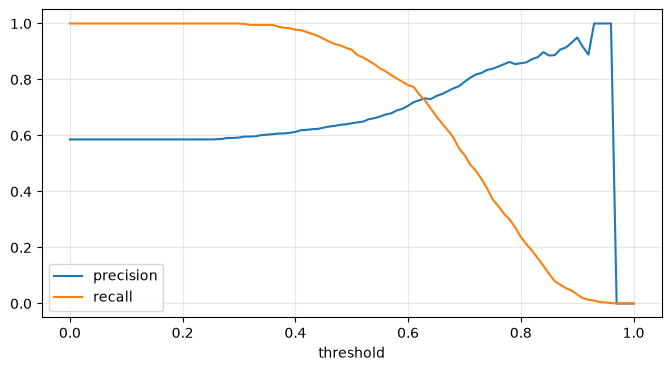

In [6]:
plt.figure(figsize=(8, 4))
plt.plot(scores.threshold, scores.precision, label='precision')
plt.plot(scores.threshold, scores.recall, label='recall')
plt.xlabel('threshold')
plt.legend()
plt.grid(alpha=0.3)


In [7]:
nonzero = scores[(scores.precision > 0) | (scores.recall > 0)].copy()
nonzero['gap'] = (nonzero.precision - nonzero.recall).abs()
nonzero.sort_values('gap').head()


,threshold,precision,recall,f1,gap
63,0.63,0.732759,0.725256,0.728988,0.007503
62,0.62,0.725914,0.745734,0.735690,0.019820
64,0.64,0.729875,0.696246,0.712664,0.033629
61,0.61,0.719048,0.773038,0.745066,0.053990
65,0.65,0.741021,0.668942,0.703139,0.072079


**Q3: 0.63**, where precision is 0.733 and recall 0.725.


## Q4 - F1


In [8]:
scores.sort_values('f1', ascending=False).head()


,threshold,precision,recall,f1
41,0.41,0.619048,0.976109,0.757616
42,0.42,0.620087,0.969283,0.756325
43,0.43,0.622517,0.962457,0.756032
45,0.45,0.628118,0.945392,0.754768
44,0.44,0.623608,0.955631,0.754717


**Q4: 0.41**, F1 of 0.758.

The top is flat - 0.41 through 0.46 all sit between 0.754 and 0.758. At the maximum the
model is recalling almost everything (0.976) at the cost of precision (0.619), so F1 is
rewarding a fairly aggressive threshold here.


## Q5 - 5-fold cross validation


In [9]:
y_full = df_full_train['converted'].values
X_full = df_full_train.drop(columns=['converted'])


def cross_validate(C):
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []

    for train_idx, val_idx in kfold.split(X_full):
        d_train = X_full.iloc[train_idx]
        d_val = X_full.iloc[val_idx]

        v = DictVectorizer(sparse=False)
        Xt = v.fit_transform(d_train[features].to_dict(orient='records'))
        Xv = v.transform(d_val[features].to_dict(orient='records'))

        m = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        m.fit(Xt, y_full[train_idx])

        scores.append(roc_auc_score(y_full[val_idx], m.predict_proba(Xv)[:, 1]))

    return np.array(scores)


fold_scores = cross_validate(1.0)
fold_scores.round(4), round(fold_scores.std(), 3)


(array([0.7306, 0.7296, 0.7363, 0.7412, 0.7209]), np.float64(0.007))

**Q5: 0.007.**

Folds run from 0.721 to 0.741, mean 0.732 - which matches the single validation split
from Q2 almost exactly.


## Q6 - tuning C


In [10]:
rows = []
for C in [0.000001, 0.001, 1]:
    s = cross_validate(C)
    rows.append({'C': C, 'mean': round(s.mean(), 3), 'std': round(s.std(), 3)})

pd.DataFrame(rows).set_index('C')


,mean,std
C,,
0.000001,0.617,0.019
0.001000,0.749,0.010
1.000000,0.732,0.007


**Q6: 0.001**, mean AUC 0.749.

C = 1 gives 0.732, so the lighter model generalises better here. C = 0.000001 collapses to
0.617 with the widest spread across folds, 0.019 - it is regularised past the point of
using the features.

Note this disagrees with hw03 Q6, where 0.001 was the best of a range that stopped at
0.001. Here it beats C = 1 outright, so the optimum really is around 0.001 and not just
the edge of the list.
